In [1]:
import sys
import torch
sys.path.insert(0,"../src")

from cnn_project.train import train_model
from cnn_project.model import EuroSATModel
from cnn_project.evaluate import evaluate_model
from cnn_project.data import create_data_loaders
from pathlib import Path
import matplotlib.pyplot as plt



In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("The model is using CUDA")
else:
    device = torch.device("cpu")
    print("The model is using CPU")

torch.manual_seed(42)
train_loader, val_loader, test_loader= create_data_loaders(batch_size=128)


The model is using CUDA


In [3]:
model =EuroSATModel().to(device)
checkpoint_path = Path("../Checkpoints/base_models/model1/best.pt")

model.load_state_dict(
    torch.load(checkpoint_path, map_location =device, weights_only=True)
)
model.eval()
print("Evaluating Model...")
train_correct, train_total = evaluate_model(model=model,dataset_loader=train_loader, device=device)
val_correct, val_total = evaluate_model(model=model,dataset_loader=val_loader, device=device)
test_correct, test_total = evaluate_model(model=model,dataset_loader=test_loader, device=device)

print(f" Train Accuracy: {100* train_correct/train_total:.4f} %")
print(f" Val Accuracy: {100* val_correct/val_total:.4f} %")
print(f" Test Accuracy: {100* test_correct/test_total:.4f} %")

Evaluating Model...
 Train Accuracy: 97.3935 %
 Val Accuracy: 96.3333 %
 Test Accuracy: 95.3333 %


In [4]:
# Read class metadata through TransformDataset -> Subset -> CachedEuroSAT.
class_names = val_loader.dataset.dataset.dataset.classes
num_classes = len(class_names)

matrix = torch.zeros([num_classes, num_classes], dtype=torch.long)
mistakes = []

model.eval()
with torch.inference_mode():
    for images, labels in val_loader:
        predictions = model(images.to(device)).argmax(dim=1).cpu()

        for index, (true, predicted) in enumerate(zip(labels, predictions)):
            matrix[true.item(), predicted.item()] +=1

            if true != predicted:
                mistakes.append((
                    images[index].clone(),
                    true.item(),
                    predicted.item(),
                ))


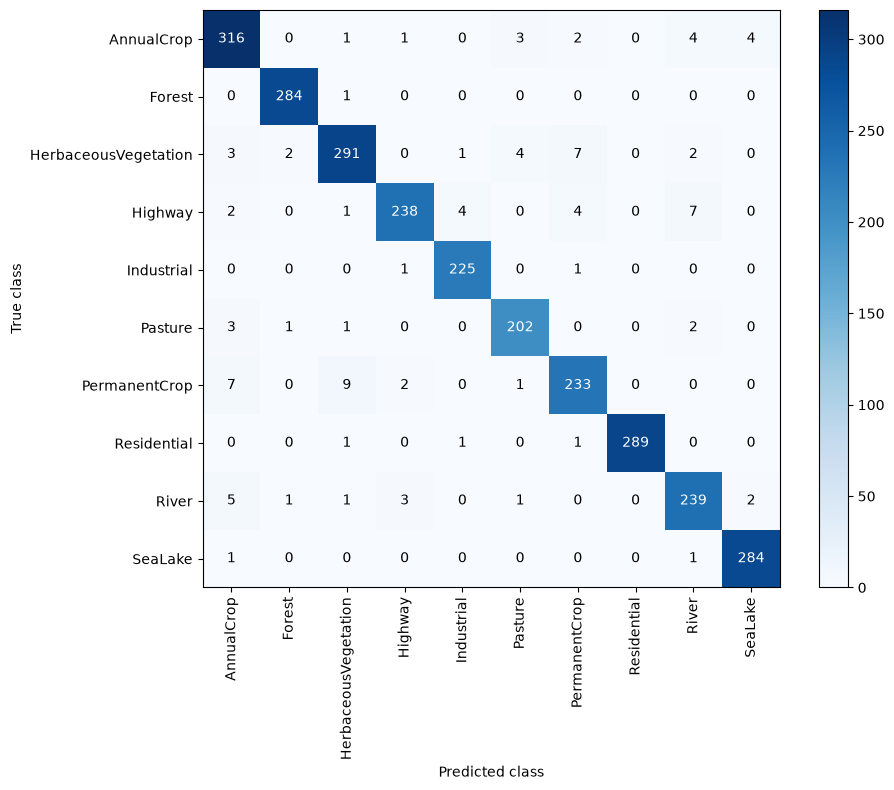

In [5]:
fig, ax = plt.subplots(figsize=(10, 8))
heatmap = ax.imshow(matrix.numpy(), cmap="Blues")
fig.colorbar(heatmap, ax=ax)

ax.set_xticks(range(num_classes), labels=class_names, rotation=90)
ax.set_yticks(range(num_classes), labels=class_names)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")

for row in range(num_classes):
    for col in range(num_classes):
        count = matrix[row, col].item()
        color = "white" if count > matrix.max().item() / 2 else "black"
        ax.text(col, row, str(count), ha="center", va="center", color=color)

plt.tight_layout()
plt.show()

Total incorrect predictions from validation dataset: 99


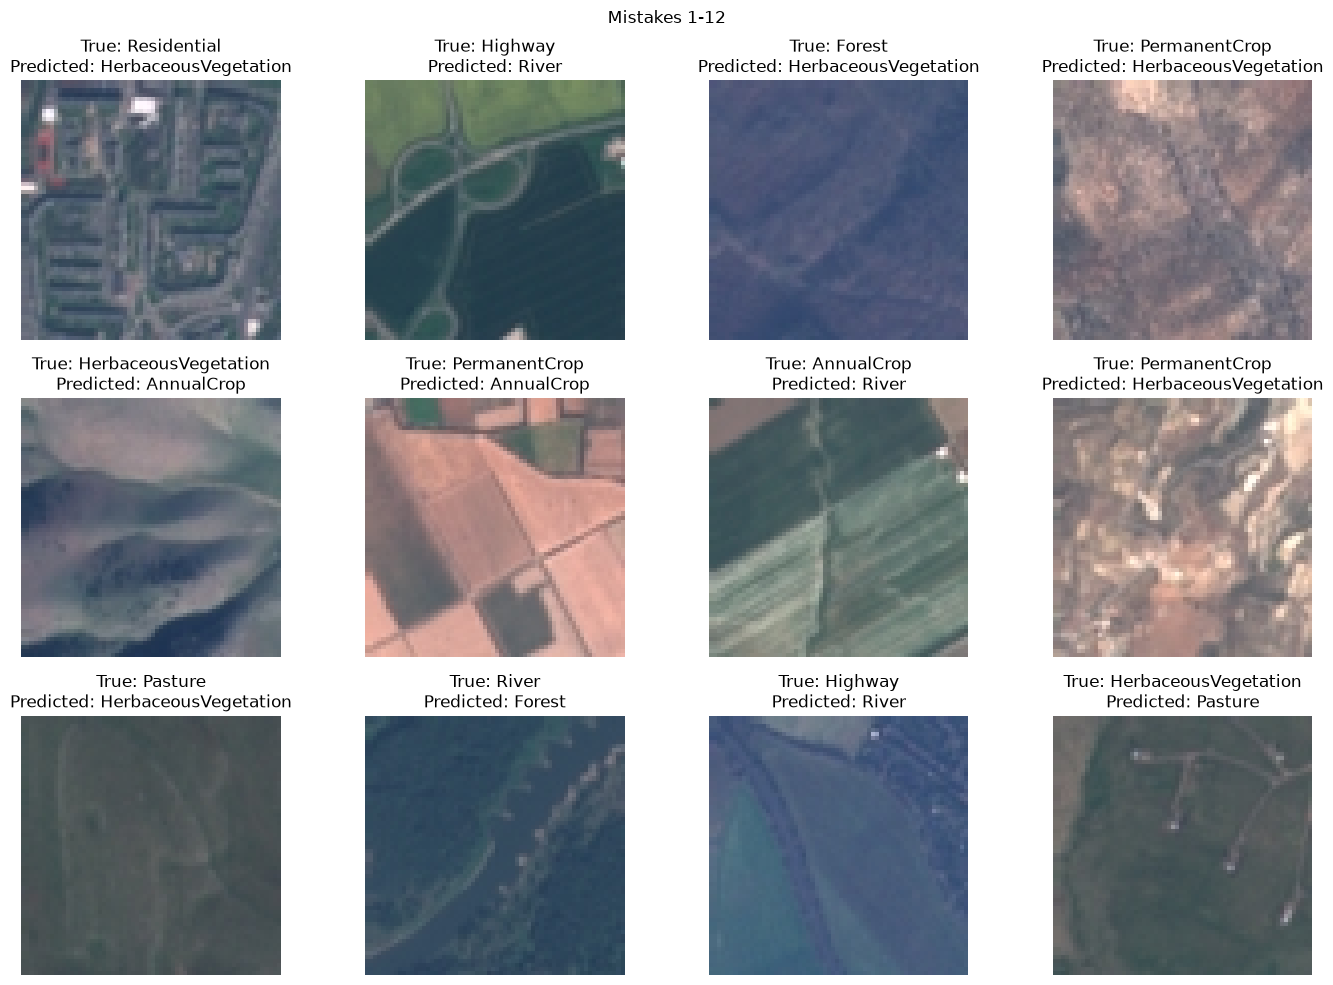

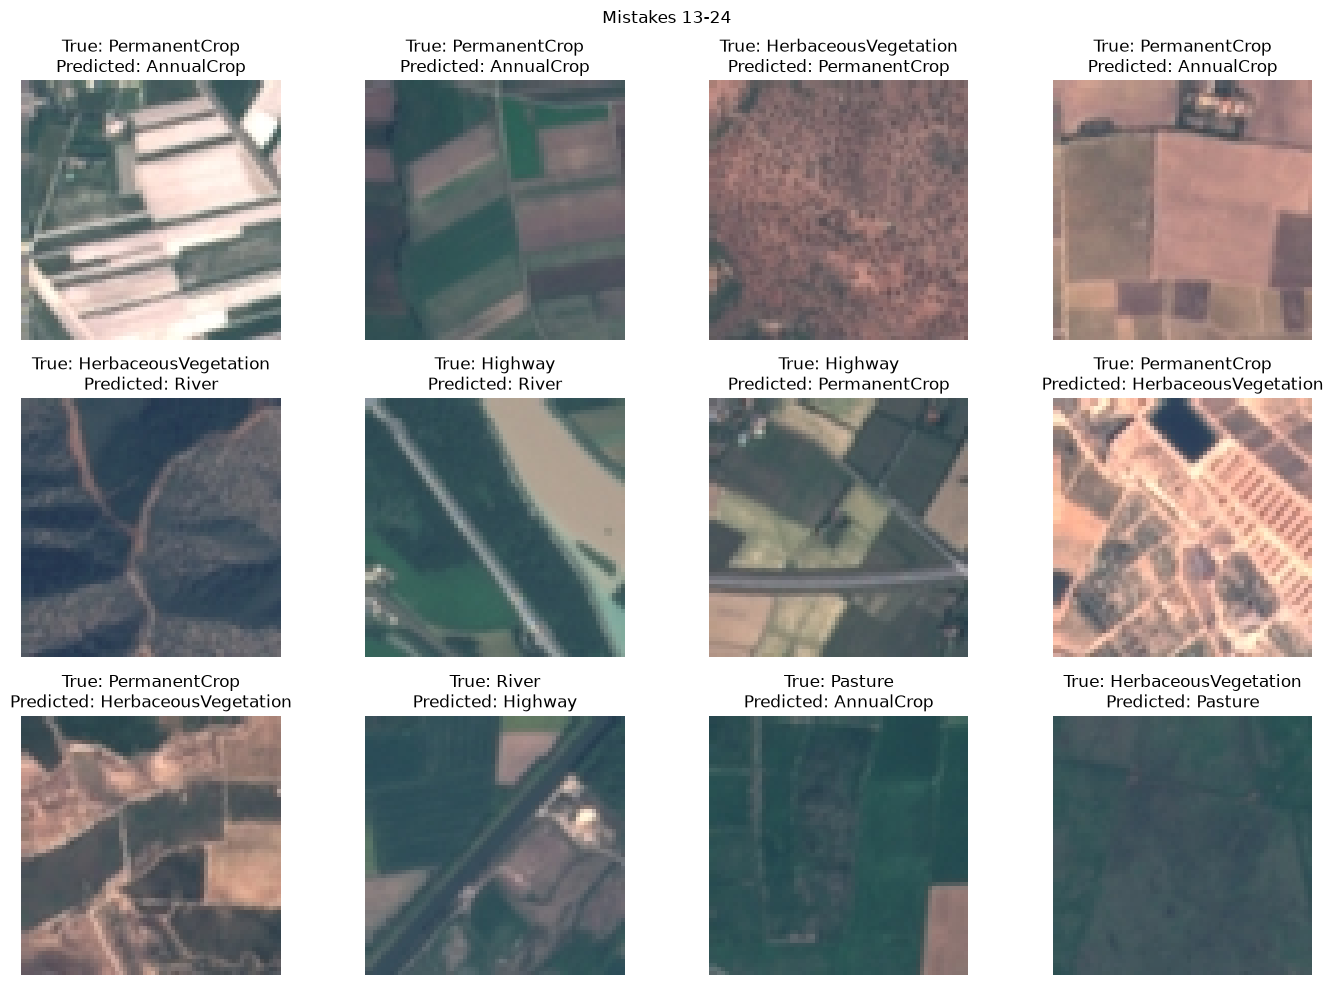

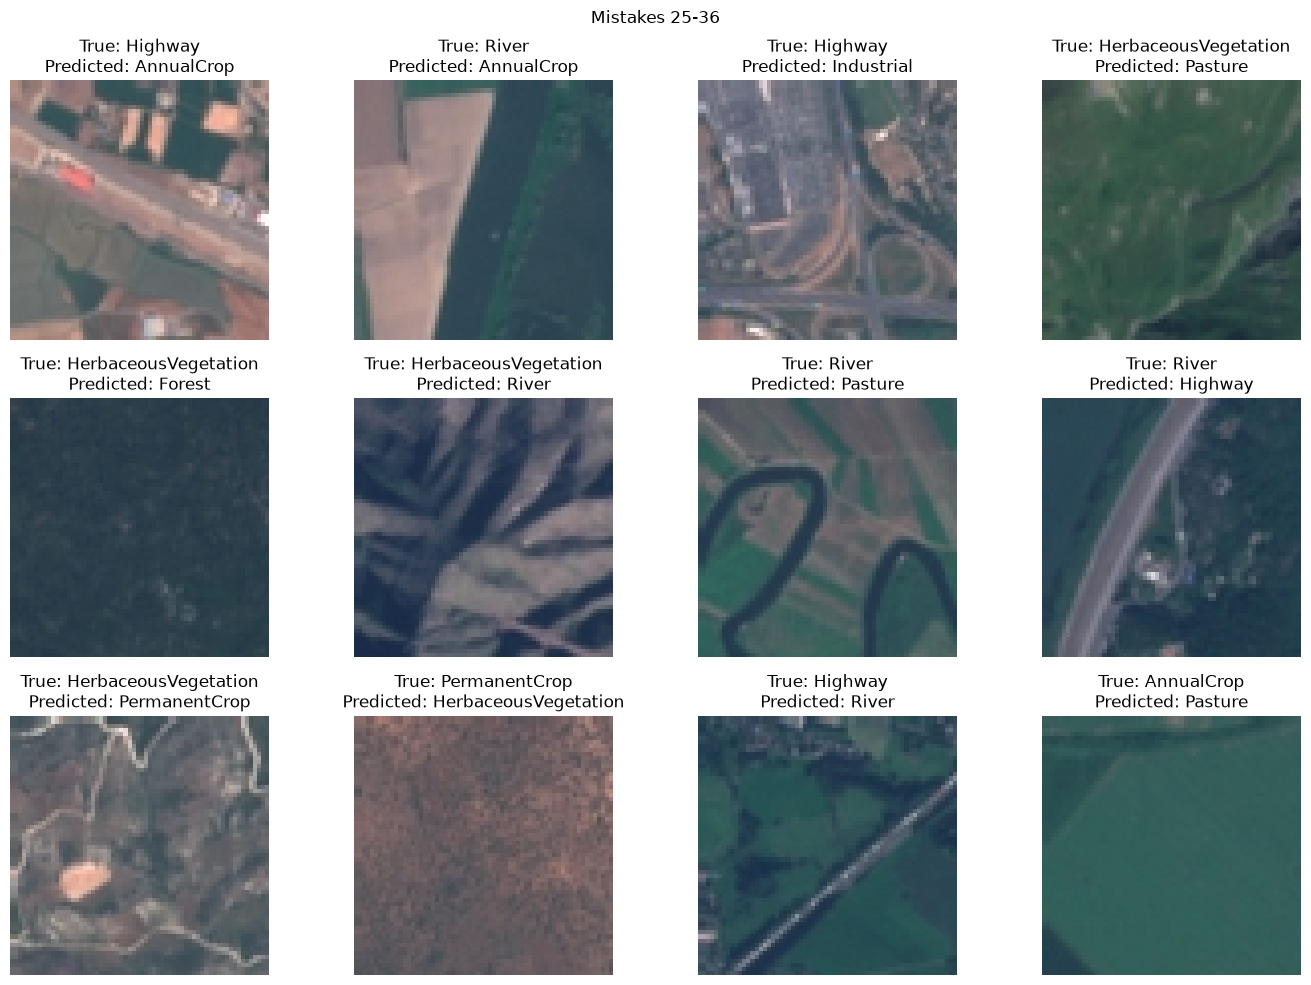

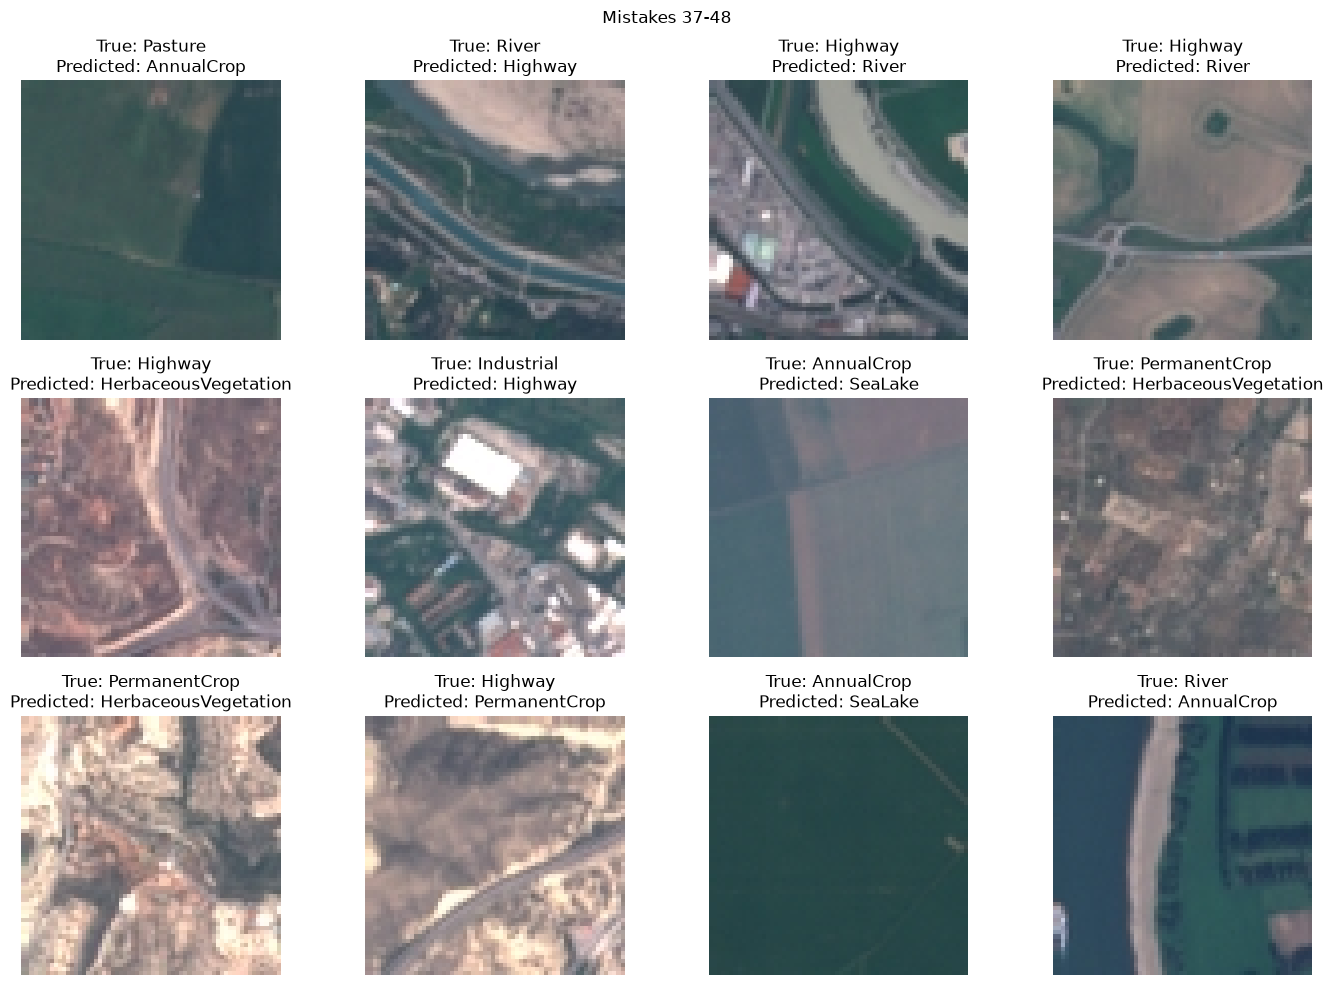

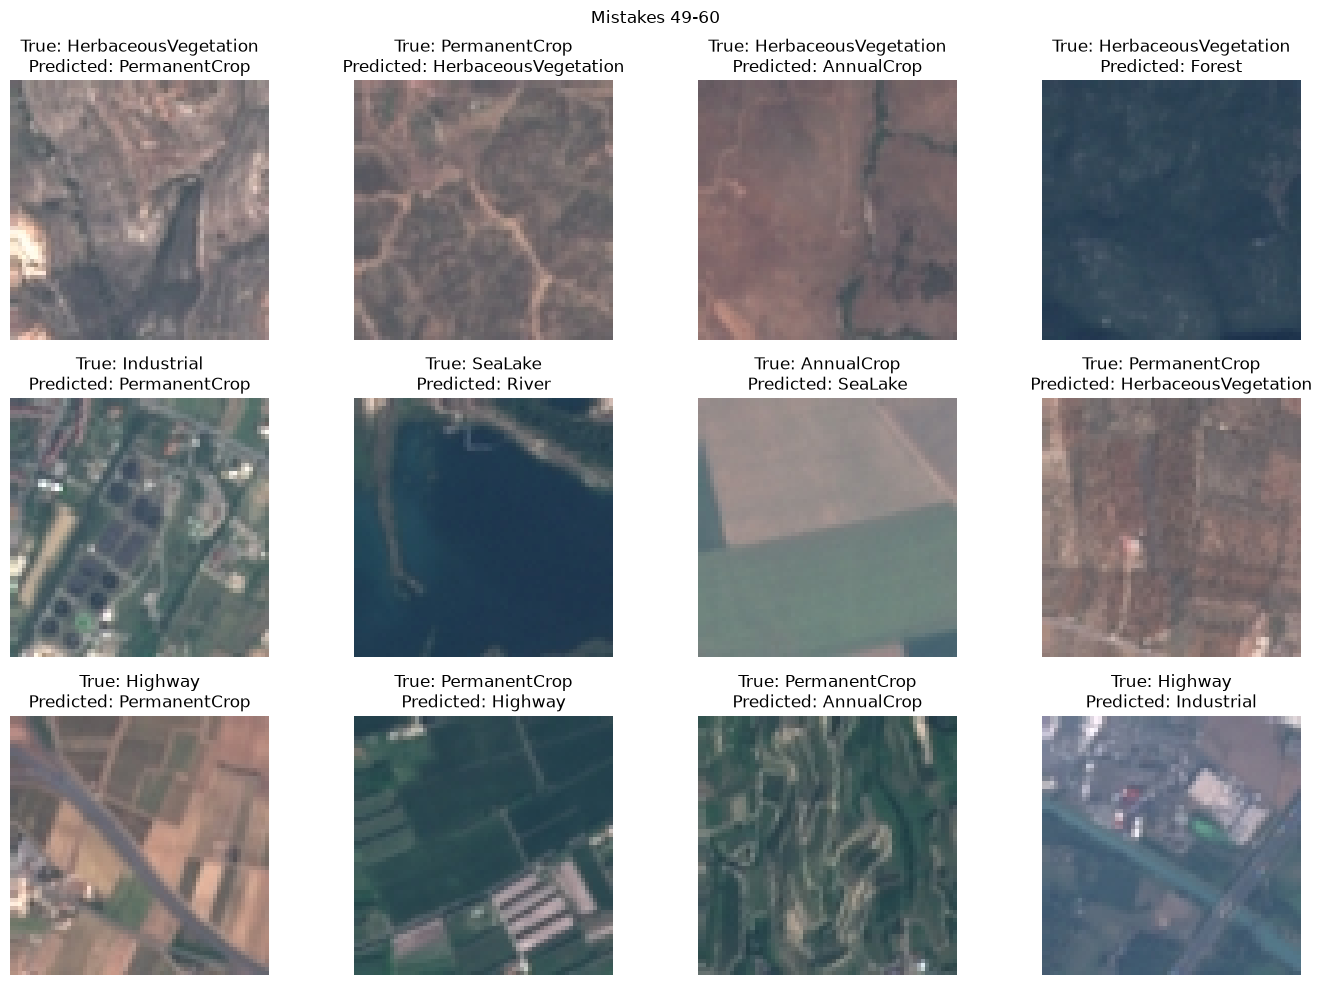

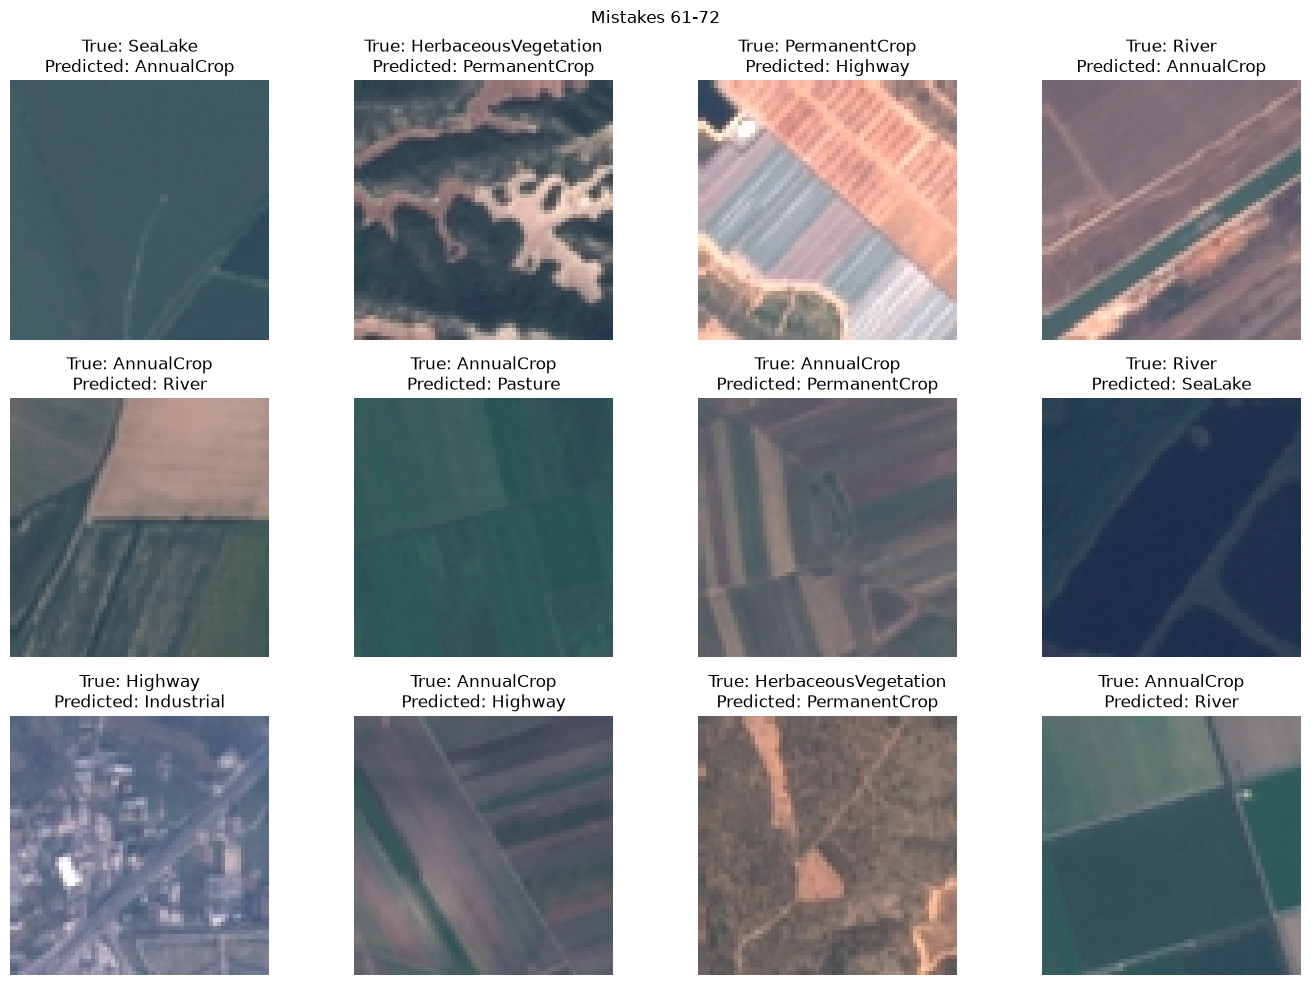

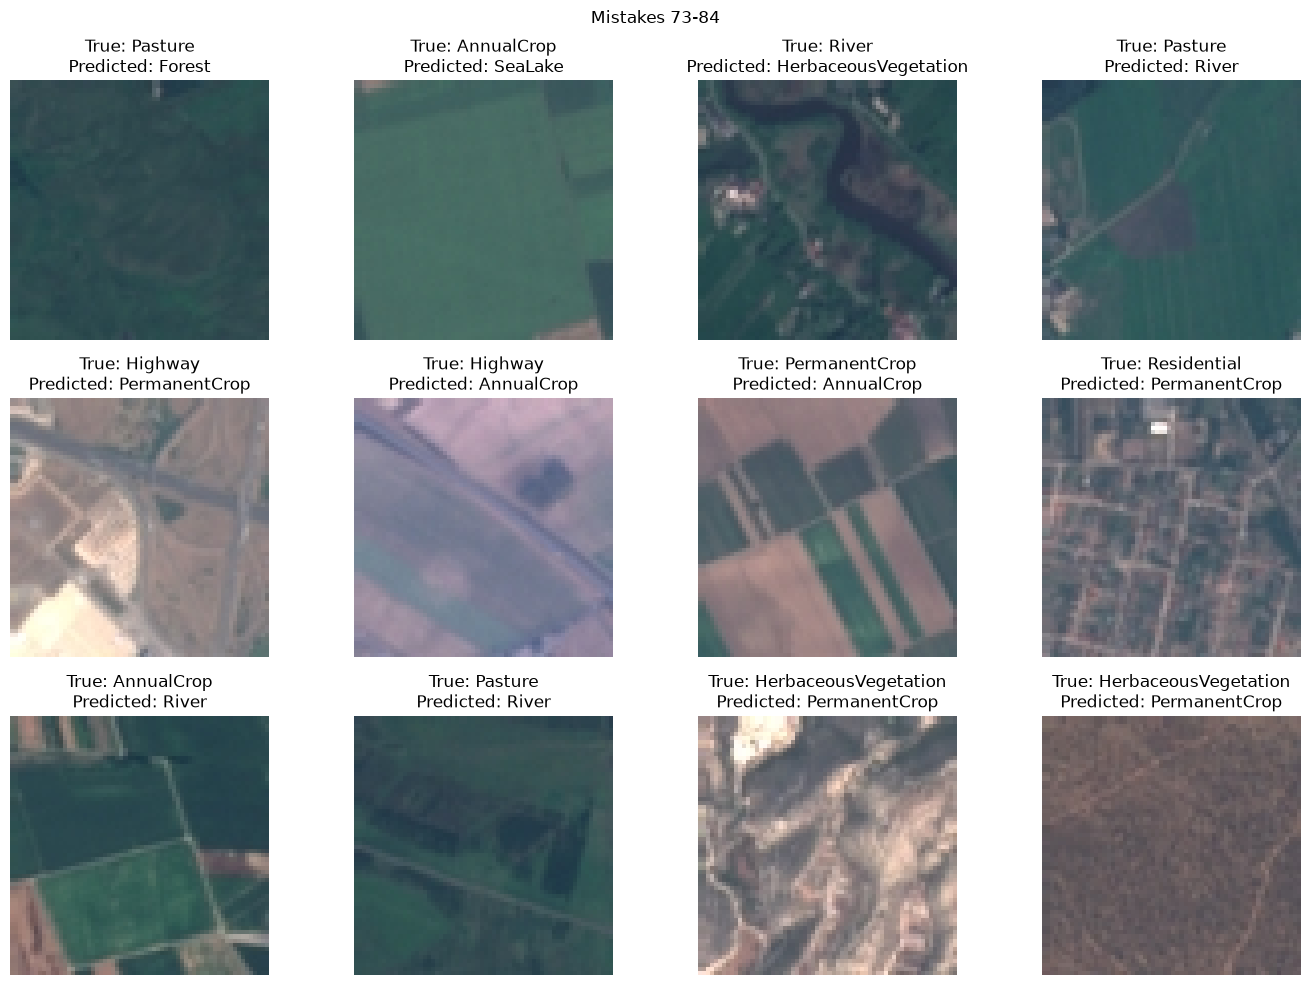

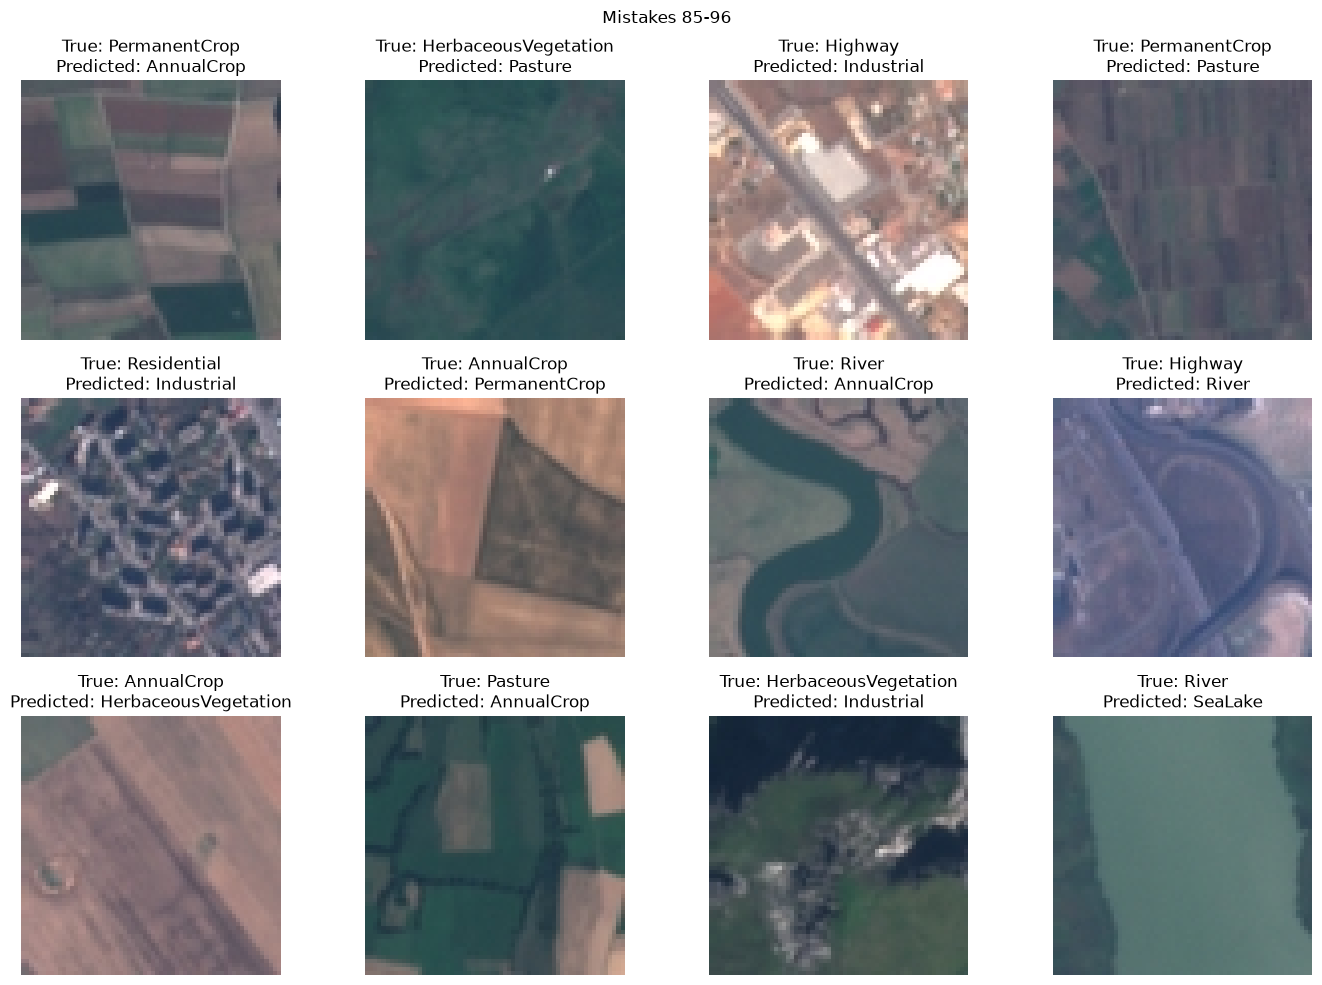

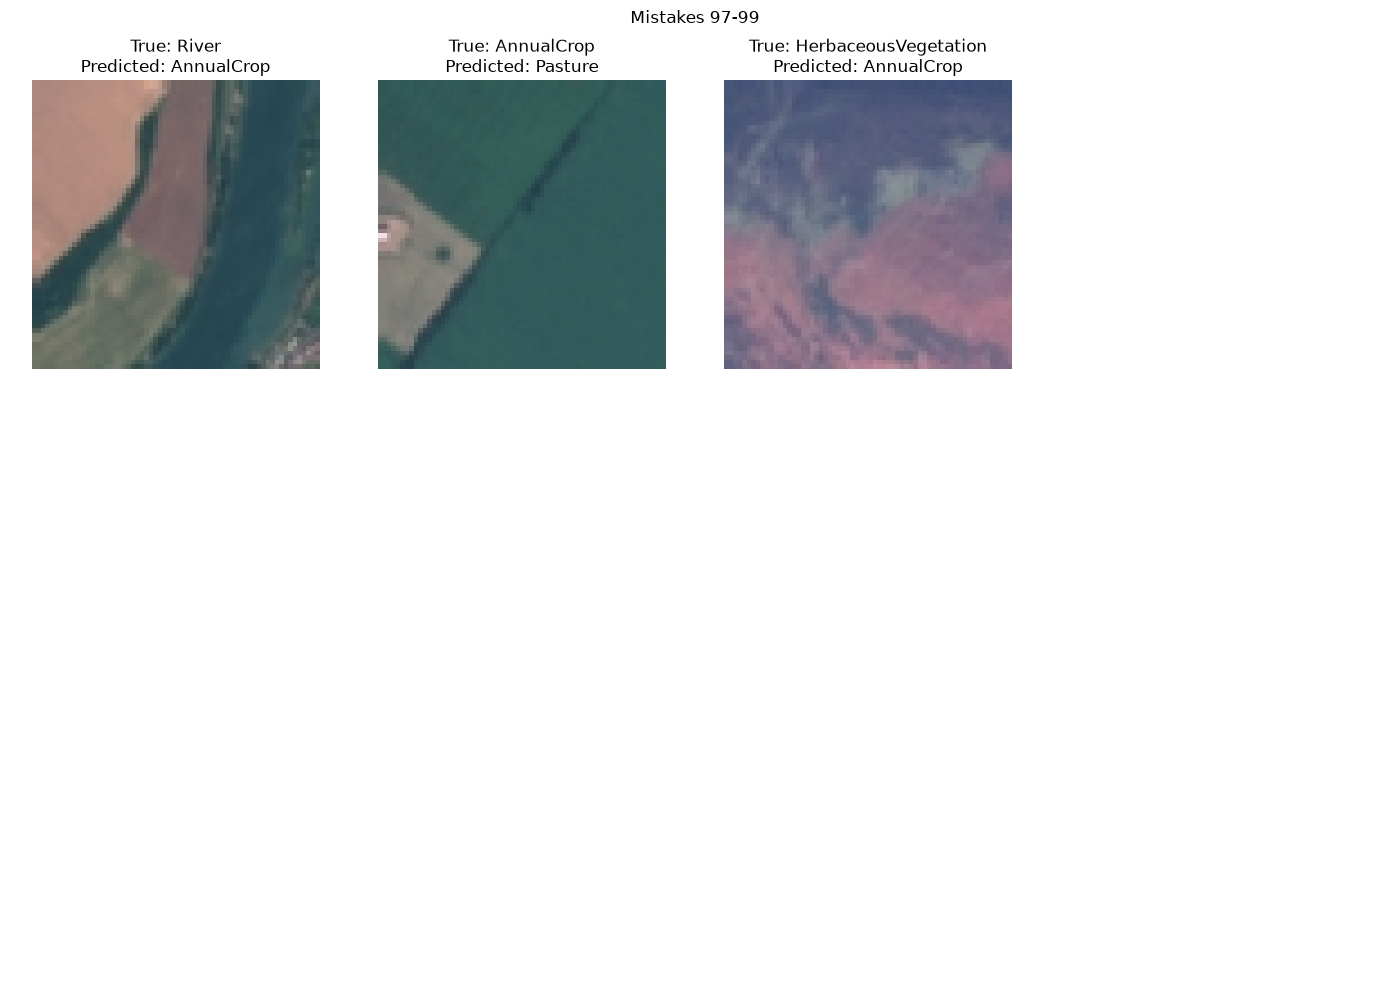

In [6]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

print(f"Total incorrect predictions from validation dataset: {len(mistakes)}")

for start in range(0, len(mistakes), 12):
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))

    for ax in axes.flat:
        ax.axis("off")

    for ax, (image, true, predicted) in zip(
        axes.flat, mistakes[start:start + 12]
    ):
        display_image = (image * std + mean).clamp(0, 1)
        ax.imshow(display_image.permute(1, 2, 0))
        ax.set_title(
            f"True: {class_names[true]}\n"
            f"Predicted: {class_names[predicted]}"
        )

    fig.suptitle(
        f"Mistakes {start + 1}-{min(start + 12, len(mistakes))}"
    )
    plt.tight_layout()
    plt.show()
    plt.close(fig)
